In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Escribe el nombre del archivo final (sin extensión): Texto
 CONVERSOR DE IMAGEN PARA POV

Selecciona una imagen:


Saving ebb311c0-8eed-4c8e-b448-072c52763b68.png to ebb311c0-8eed-4c8e-b448-072c52763b68.png

Archivo original: ebb311c0-8eed-4c8e-b448-072c52763b68.png
Formato original: PNG
Resolución original: (1254, 1254)
Modo original: RGB

 CONVERSION TERMINADA
Resolución final: (200, 200)
Modo final: RGB
Formato final: BMP
Modo utilizado: RECORTAR
Guardado en: /content/drive/MyDrive/TESIS_POV/Imagenes/Texto.bmp

Vista previa:


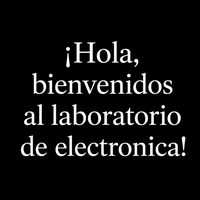

In [5]:
from google.colab import files
from google.colab import drive
from PIL import Image, ImageOps
import os
import io



# ============================================================
# CONFIGURACION
# ============================================================

ANCHO = 200
ALTO = 200

# Opciones:
# "RECORTAR"
# "AJUSTAR"
# "ESTIRAR"
MODO = "RECORTAR"

# Color del fondo para transparencia o modo AJUSTAR
COLOR_FONDO = (0, 0, 0)

# Carpeta base de salida
OUTPUT_DIR = "/content/drive/MyDrive/TESIS_POV/Imagenes"


# ============================================================
# CREAR CARPETA SI NO EXISTE
# ============================================================

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# PEDIR NOMBRE DEL ARCHIVO FINAL
# ============================================================

nombre_salida = input(
    "Escribe el nombre del archivo final (sin extensión): "
).strip()

if not nombre_salida:
    raise Exception("Debes escribir un nombre para el archivo final.")

# Limpiar caracteres problemáticos
nombre_salida = nombre_salida.replace("/", "_").replace("\\", "_")

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    nombre_salida + ".bmp"
)


# ============================================================
# SUBIR IMAGEN
# ============================================================

print("===================================")
print(" CONVERSOR DE IMAGEN PARA POV")
print("===================================")
print()
print("Selecciona una imagen:")

uploaded = files.upload()

if not uploaded:
    raise Exception("No se seleccionó ninguna imagen.")

nombre_archivo = list(uploaded.keys())[0]
datos_archivo = uploaded[nombre_archivo]


# ============================================================
# ABRIR IMAGEN
# ============================================================

imagen = Image.open(io.BytesIO(datos_archivo))

print()
print("Archivo original:", nombre_archivo)
print("Formato original:", imagen.format)
print("Resolución original:", imagen.size)
print("Modo original:", imagen.mode)


# ============================================================
# CORREGIR ROTACION EXIF
# ============================================================

imagen = ImageOps.exif_transpose(imagen)


# ============================================================
# TRANSPARENCIA -> RGB
# ============================================================

if imagen.mode in ("RGBA", "LA"):
    imagen_rgba = imagen.convert("RGBA")
    fondo = Image.new("RGB", imagen_rgba.size, COLOR_FONDO)
    fondo.paste(imagen_rgba, mask=imagen_rgba.getchannel("A"))
    imagen = fondo
else:
    imagen = imagen.convert("RGB")


# ============================================================
# CONVERTIR A 200 x 200
# ============================================================

if MODO == "RECORTAR":

    imagen_final = ImageOps.fit(
        imagen,
        (ANCHO, ALTO),
        method=Image.Resampling.LANCZOS,
        centering=(0.5, 0.5)
    )

elif MODO == "AJUSTAR":

    imagen_redimensionada = ImageOps.contain(
        imagen,
        (ANCHO, ALTO),
        method=Image.Resampling.LANCZOS
    )

    imagen_final = Image.new(
        "RGB",
        (ANCHO, ALTO),
        COLOR_FONDO
    )

    x = (ANCHO - imagen_redimensionada.width) // 2
    y = (ALTO - imagen_redimensionada.height) // 2

    imagen_final.paste(imagen_redimensionada, (x, y))

elif MODO == "ESTIRAR":

    imagen_final = imagen.resize(
        (ANCHO, ALTO),
        Image.Resampling.LANCZOS
    )

else:
    raise ValueError(
        "MODO inválido. Usa RECORTAR, AJUSTAR o ESTIRAR."
    )


# ============================================================
# ASEGURAR FORMATO RGB
# ============================================================

imagen_final = imagen_final.convert("RGB")


# ============================================================
# GUARDAR EN GOOGLE DRIVE
# ============================================================

imagen_final.save(OUTPUT_PATH, "BMP")


# ============================================================
# INFORMACION FINAL
# ============================================================

print()
print("===================================")
print(" CONVERSION TERMINADA")
print("===================================")
print("Resolución final:", imagen_final.size)
print("Modo final:", imagen_final.mode)
print("Formato final: BMP")
print("Modo utilizado:", MODO)
print("Guardado en:", OUTPUT_PATH)


# ============================================================
# VISTA PREVIA
# ============================================================

print()
print("Vista previa:")
display(imagen_final)